<a href="https://colab.research.google.com/github/tphan356/household-object-classification/blob/main/code/household_object_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Household Object Classification

A deep learning project focused on classifying common household objects using computer vision, with potential applications in intelligent home robotics.

## Set up

In [1]:
!pip install -q kagglehub

### Import library

In [2]:
import fastai
import kagglehub
import numpy as np
import pandas as pd
import torch

from pathlib import Path
from fastai.vision.all import *
from fastcore.all import *

### Check instrallation

In [3]:
print("Fastai version:", fastai.__version__)
print("PyTorch version:", torch.__version__)
print("GPU available", torch.cuda.is_available())

Fastai version: 2.8.12
PyTorch version: 2.11.0+cu130
GPU available True


## Domain Problem

Recognizing household objects is an important capability for intelligent home robots, such as robot vacuum cleaners. These robots need to identify objects in their environment to better understand their surroundings and support navigation.

The goal of this project is to develop an image classification model that can recognize five common household objects: bed, chair, sofa, swivel chair, and table.

## Analytic approach

I will take a predictive approach in this project. We will train an image classifier that can recognize and classify five common household objects: chair, table, refrigerator, TV, and wardrobe (almirah). The model will learn visual features from labeled images and use them to predict the category of new, unseen images.

## Household Object Classifier

The dataset comes from [Furniture Detector on Kaggle](https://www.kaggle.com/datasets/akkithetechie/furniture-detector).

The dataset contains five furniture categories:

1. Bed
2. Chair
3. Sofa
4. Swivel Chair
5. Table

We will use these labeled images to train a multiclass image classification model. Before training, we will examine the data, check for duplicates, and split the images into training and validation sets.

### Download the dataset

In [4]:
path = Path(kagglehub.dataset_download("akkithetechie/furniture-detector"))

print("Dataset location:", path)

Using Colab cache for faster access to the 'furniture-detector' dataset.
Dataset location: /kaggle/input/furniture-detector


### Examine the downloaded files

In [5]:
for item in sorted(path.iterdir()):
    print(item.name)

furniture-images
img


### Get all image files

In [6]:
image_root = path / "furniture-images"

if not image_root.exists():
    image_root = path

file_names = get_image_files(image_root)

print("Total image files:", len(file_names))
print("Sample image paths:")

for file in file_names[:5]:
    print(file.relative_to(path))

Total image files: 4447
Sample image paths:
furniture-images/img/val/sofa/00000233.jpg
furniture-images/img/val/sofa/00000277.jpg
furniture-images/img/val/sofa/00000253.jpg
furniture-images/img/val/sofa/00000211.jpg
furniture-images/img/val/sofa/00000267.jpg


### Define the labeling function

In [7]:
class_names = {"bed", "chair", "sofa", "swivelchair", "table"}

def label_function(file_name):
    for folder in Path(file_name).parents:
        name = ''.join(c for c in folder.name.lower() if c.isalpha())

        if name in class_names:
            return name

    raise ValueError(f"No category found for {file_name}")

In [8]:
labeled_files = []

for file in file_names:
    try:
        label_function(file)
        labeled_files.append(file)
    except ValueError:
        pass

class_counts = Counter(label_function(f) for f in labeled_files)

for category, count in sorted(class_counts.items()):
    print(f"{category}: {count} images")

print("Total labeled images:", len(labeled_files))
print("Unlabeled images skipped:", len(file_names) - len(labeled_files))

assert set(class_counts) == class_names, "Check the dataset folder structure."

bed: 1000 images
chair: 1000 images
sofa: 1000 images
swivelchair: 1000 images
table: 447 images
Total labeled images: 4447
Unlabeled images skipped: 0


### Display multiple sample images

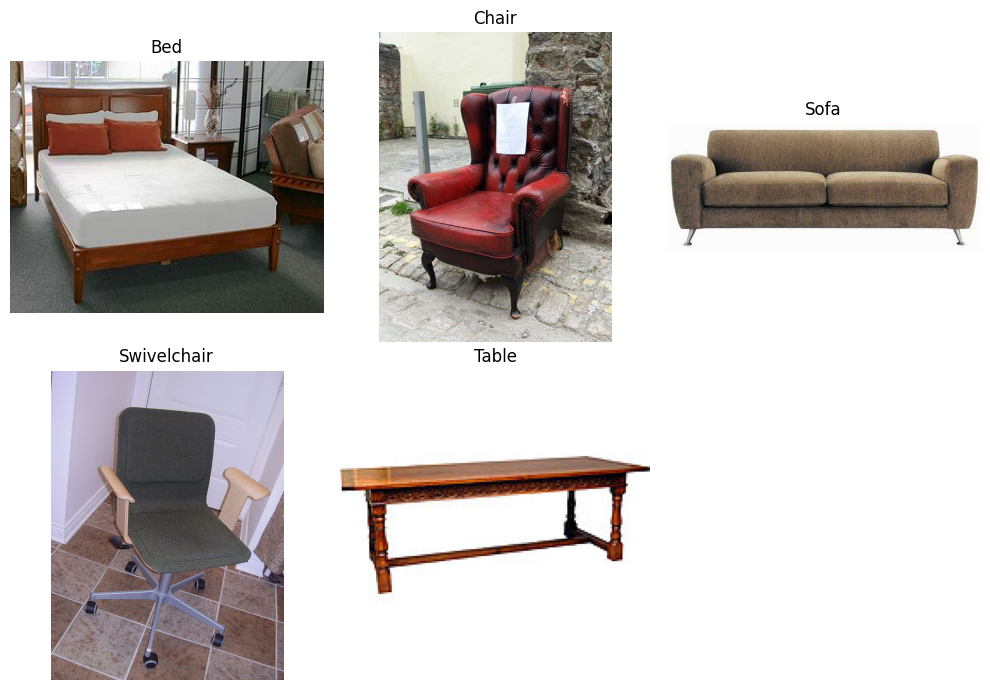

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(10, 7))

for ax, category in zip(axes.flat, sorted(class_names)):
    images = [f for f in labeled_files if label_function(f) == category]

    sample = random.choice(images)

    ax.imshow(PILImage.create(sample))
    ax.set_title(category.capitalize())
    ax.axis('off')

for ax in axes.flat[5:]:
    ax.axis('off')

plt.tight_layout()
plt.show()

## Data Processing

The images are organized into five furniture categories, so we can use the folder names as image labels.

Processing of the images (input) and their labels (output) will be done as we set up the neural network model. Since the neural network requires a consistent input image size, we will resize the images before training.

I will first resize images to 460 × 460 pixels, then apply data augmentation to produce 224 × 224 images.

### Function to add a new code cell

In [11]:
def label_function(file_name):
    return file_name.parent.name.replace('_dataset', '').replace(' dataset', '')

In [12]:
for folder in sorted(path.iterdir()):

    images = get_image_files(folder)

    print(f"{folder.name} -> {label_function(images[0])}")

furniture-images -> sofa
img -> sofa


## Set up DataBlock

In [13]:
dblock = DataBlock(
    blocks = (ImageBlock, CategoryBlock),
    get_items = get_image_files,
    get_y = label_function,
    splitter = RandomSplitter(seed=42),                       # Split images into 80% training and 20% validation
    item_tfms = Resize(460),                                  # Resize each imgage to 460x460 before batching
    batch_tfms = aug_transforms(size = 224, min_scale = 0.75) # Apply data augmentation and resize images to 224x224
)

### Load the data

In [14]:
dls = dblock.dataloaders(path)

## Exploratory data analysis

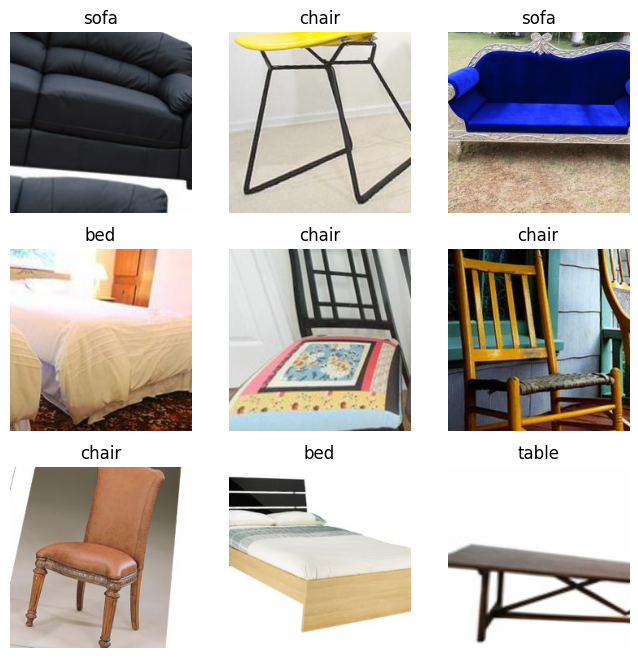

In [15]:
dls.show_batch(max_n = 9, figsize=(8,8))

### Verify dataset

In [16]:
print("Categories:", dls.vocab)
print("Training images:", len(dls.train_ds))
print("Validation images:", len(dls.valid_ds))

Categories: ['bed', 'chair', 'sofa', 'swivelchair', 'table']
Training images: 7116
Validation images: 1778


## Modeling - Fine tuning

I will use a deep neural network to build the classification model. Rather than training a network from scratch, we will modify an existing deep neural network to solve the problem of recognizing dogs vs. cats.

The model will be based on the ResNet-34 deep neural network that was trained on the [ImageNet](https://www.image-net.org/) dataset.

![picture](https://storage.googleapis.com/kaggle-datasets-images/6978/10038/d9e74a548a8cdca167b38520ac8bf405/data-original.png?t=2017-12-13-20-32-53)

The ImageNet data set consists of images of many types.

I will use transfer learning to fine-tune the model to classify images as bed, chair, sofa, swivel chair, or table.

### Create the neural network

In [17]:
learn = vision_learner(dls, resnet34, metrics = error_rate)

### Fine-tune the model

In [18]:
learn.fine_tune(1)

epoch,train_loss,valid_loss,error_rate,time
0,0.473569,0.138309,0.034308,01:17


epoch,train_loss,valid_loss,error_rate,time
0,0.133266,0.054966,0.014623,01:10


Model Performance

The ResNet34 model achieved 98.54% validation accuracy, with an error rate of 0.014623 after fine-tuning. The training loss decreased from 0.473569 to 0.133266, while the validation loss decreased from 0.138309 to 0.054966.

## Model Evaluation

I will use a confusion matrix to evaluate the model's classification performance across the five household object categories. The confusion matrix shows how many images were correctly classified and which categories were confused with one another.

In [19]:
interp = ClassificationInterpretation.from_learner(learn)

Plot the confusion matrix, which shows the number of images in the validation set that were correctly and incorrectly classified by the model.

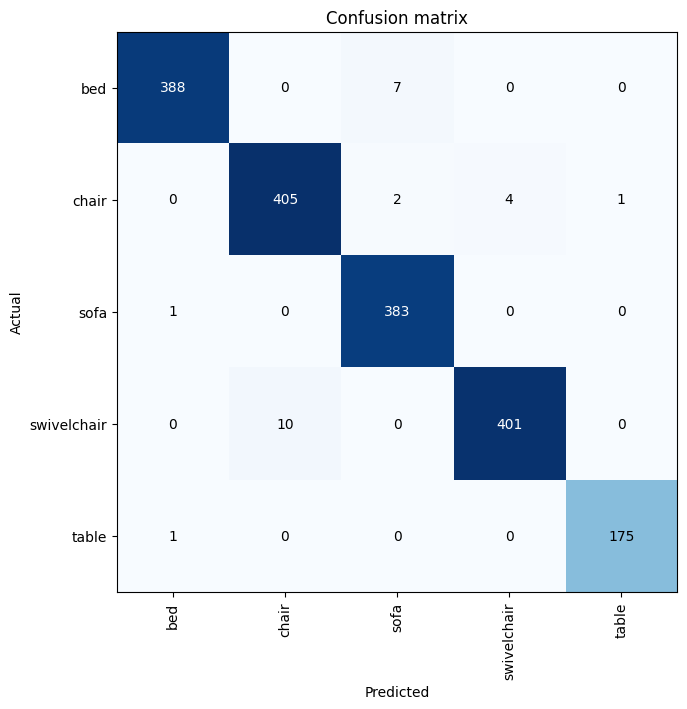

In [20]:
interp.plot_confusion_matrix(figsize=(7, 7))

In [22]:
cm = interp.confusion_matrix()

print(f"Error rate: {(cm.sum() - cm.trace()) / cm.sum():.2%}")

Error rate: 1.46%


### Identify the most confused categories

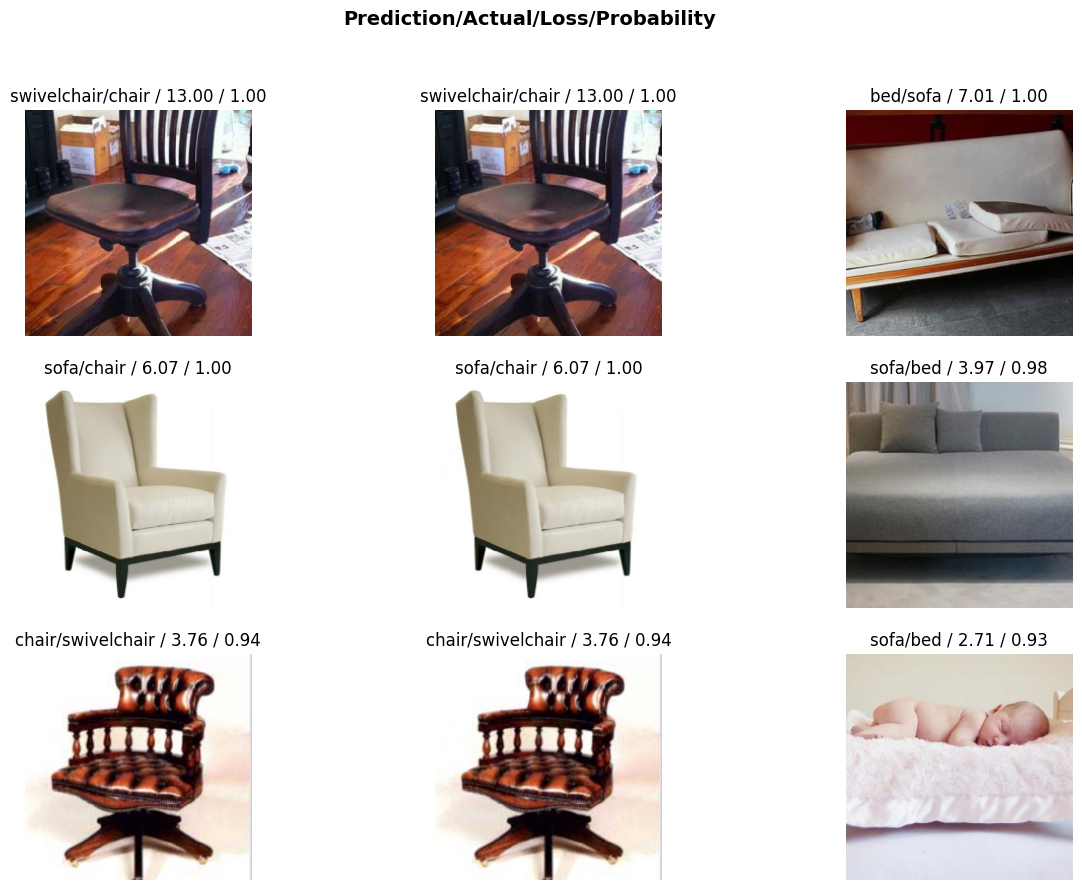

In [27]:
interp.plot_top_losses(9, figsize=(15, 10))